# Dark Ecology Intelligence (DEI) — Phase 1: Master Setup Notebook
**Artificial Neural Networks — Problem-Based Learning (ANN PBL)**

---

## 1. Executive Summary & Objective

This master notebook implements and documents the complete **Phase 1: Research Setup, Geographical Definition, and Dataset Source Inventory** for the Dark Ecology Intelligence (DEI) project.

Our academic research investigates the multidecadal relationship between **Artificial Light at Night (ALAN)**, biodiversity dynamics, ecological trophic interactions, and environmental changes across three contrasting landscapes in Southern India:
1. **Bengaluru Landscape**: Highly urbanised megacity and peri-urban expansion.
2. **Mysuru Landscape**: Peri-urban, transitional, and agrarian riverine matrix.
3. **Nilgiri–Bandipur Landscape**: Protected forest and transboundary wildlife corridor (explicitly defined as the Bandipur–Mudumalai corridor, distinct from the broader Nilgiri Biosphere Reserve).

### Phase 1 Core Tasks
1. Establish mathematically rigorous study-area boundaries and a common **5 km × 5 km spatial grid** in UTM Zone 43N (`EPSG:32643`).
2. Investigate the provisional **1992–2024 temporal scope** and address sensor discontinuities.
3. Establish the central **dataset source inventory** across 27 candidate datasets in 6 categories.
4. Empirically verify **regional availability** across Bengaluru, Mysuru, and Nilgiri–Bandipur.
5. Adhere strictly to project-wide integrity rules: **zero synthetic data**, **collect only necessary data**, and maintain clean folder-level documentation.

*Detailed sub-workflows are available in `notebooks/phase_1_setup/`:*
- `01_project_and_geographical_setup.ipynb`
- `02_dataset_source_investigation.ipynb`
- `03_regional_availability_assessment.ipynb`

## 2. Environment Setup & Relative Paths

In [1]:
# --- Locate the project root and make our utility modules importable ---
import sys
from pathlib import Path

root = Path.cwd().resolve()
while not (root / ".dei_project_root").exists():
    if root.parent == root:
        raise FileNotFoundError("Run this notebook from inside the dark_eco/ project folder.")
    root = root.parent
sys.path.insert(0, str(root / "scripts" / "utilities"))

import dei_paths as P
print("Project root:", P.ROOT)

Project root: /Users/apple/Documents/5th sem el/ANN_PBL/dark_eco


In [2]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 75)

print("Project Root:", P.ROOT)
print("Data Directory:", P.DATA)
print("Boundaries Directory:", P.BOUNDARIES)
print("Reports Directory:", P.REPORTS)

Project Root: /Users/apple/Documents/5th sem el/ANN_PBL/dark_eco
Data Directory: /Users/apple/Documents/5th sem el/ANN_PBL/dark_eco/data
Boundaries Directory: /Users/apple/Documents/5th sem el/ANN_PBL/dark_eco/geographical_boundaries
Reports Directory: /Users/apple/Documents/5th sem el/ANN_PBL/dark_eco/reports


## 3. Geographical Boundaries & 5 km × 5 km Spatial Grid

Each landscape is defined as a standardized **50 km × 50 km window** ($2,500	ext{ km}^2$), partitioned into **100 regular 5 km × 5 km grid cells** ($25.0	ext{ km}^2$ each) in **UTM Zone 43N (`EPSG:32643`)**.
Total study system: **300 grid cells covering $7,500	ext{ km}^2$**.

In [3]:
# Load boundary summary
study_areas = gpd.read_file(P.BOUNDARIES / "study_areas_summary.geojson").set_index("region_id")
b = study_areas.geometry.bounds
study_areas["lat_min"] = b.miny.round(4)
study_areas["lat_max"] = b.maxy.round(4)
study_areas["lon_min"] = b.minx.round(4)
study_areas["lon_max"] = b.maxx.round(4)
study_areas["area_km2"] = (study_areas.n_cells * (study_areas.cell_size_m / 1000)**2)

display(study_areas[["region_name", "landscape_type", "anchor", "lat_min", "lat_max", "lon_min", "lon_max", "area_km2"]])

,region_name,landscape_type,anchor,lat_min,lat_max,lon_min,lon_max,area_km2
region_id,,,,,,,,
bengaluru,Bengaluru urban-peri-urban window,highly urbanised,Central Bengaluru (Vidhana Soudha area),12.7396,13.1959,77.3577,77.8229,2500.0
mysuru,Mysuru peri-urban / transitional window,peri-urban and transitional,Mysuru city centre (Mysuru Palace area),12.0790,12.5338,76.4242,76.8866,2500.0
nilgiri_bandipur,Bandipur-Mudumalai forest window (Nilgiri-Bandipur),forest and protected-area,Karnataka-Tamil Nadu border near Moyar river (Bandipur/Mudumalai junction),11.4286,11.8832,76.3658,76.8270,2500.0


In [4]:
# Load 5km grid summary
all_grid = gpd.read_file(P.BOUNDARIES / "all_regions_5km_grid.geojson")
grid_summary = all_grid.groupby("region_id").agg(
    total_cells=("cell_id", "count"),
    min_cell_area_km2=("area_km2", "min"),
    max_cell_area_km2=("area_km2", "max")
)
display(grid_summary)

,total_cells,min_cell_area_km2,max_cell_area_km2
region_id,,,
bengaluru,100,25.0,25.0
mysuru,100,25.0,25.0
nilgiri_bandipur,100,25.0,25.0


### 3.1 Geographical Overview Map

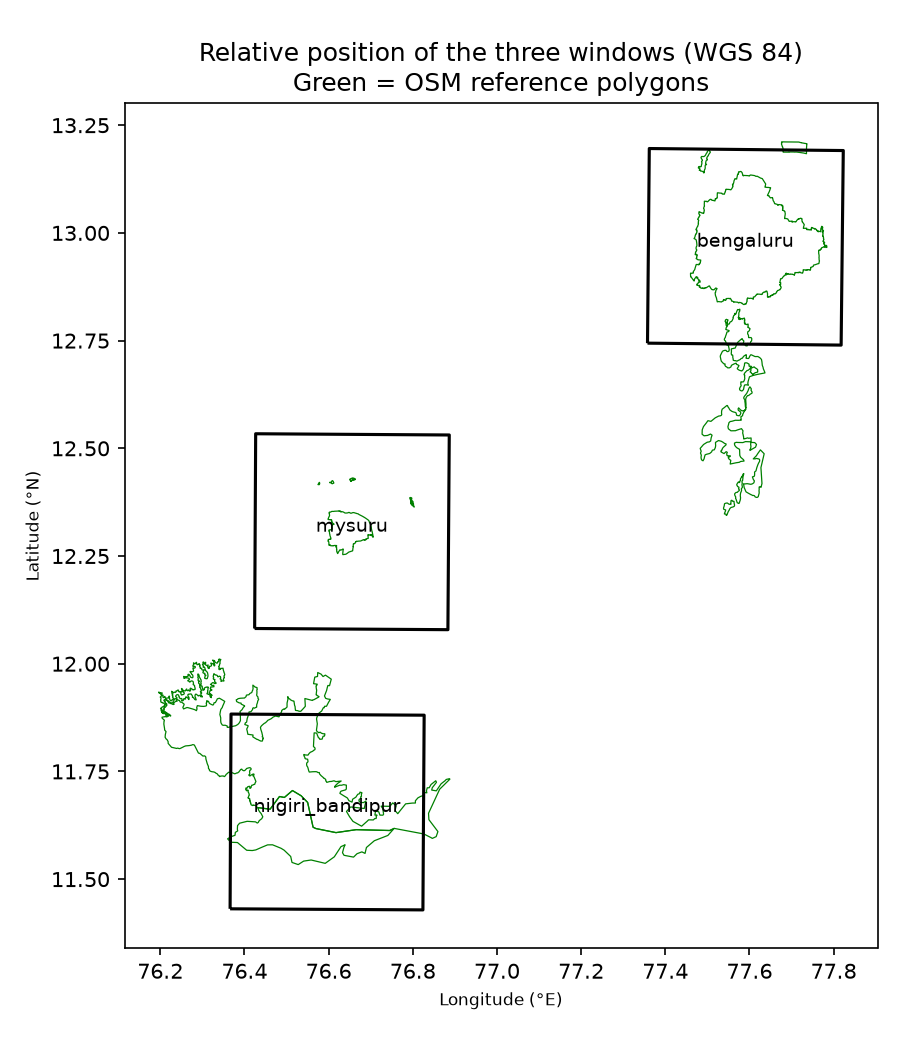

In [5]:
# Display overview map generated by the geographical setup workflow
overview_fig = P.REPORTS / "phase_1" / "figures" / "study_windows_overview.png"
if overview_fig.exists():
    display(Image(filename=str(overview_fig)))

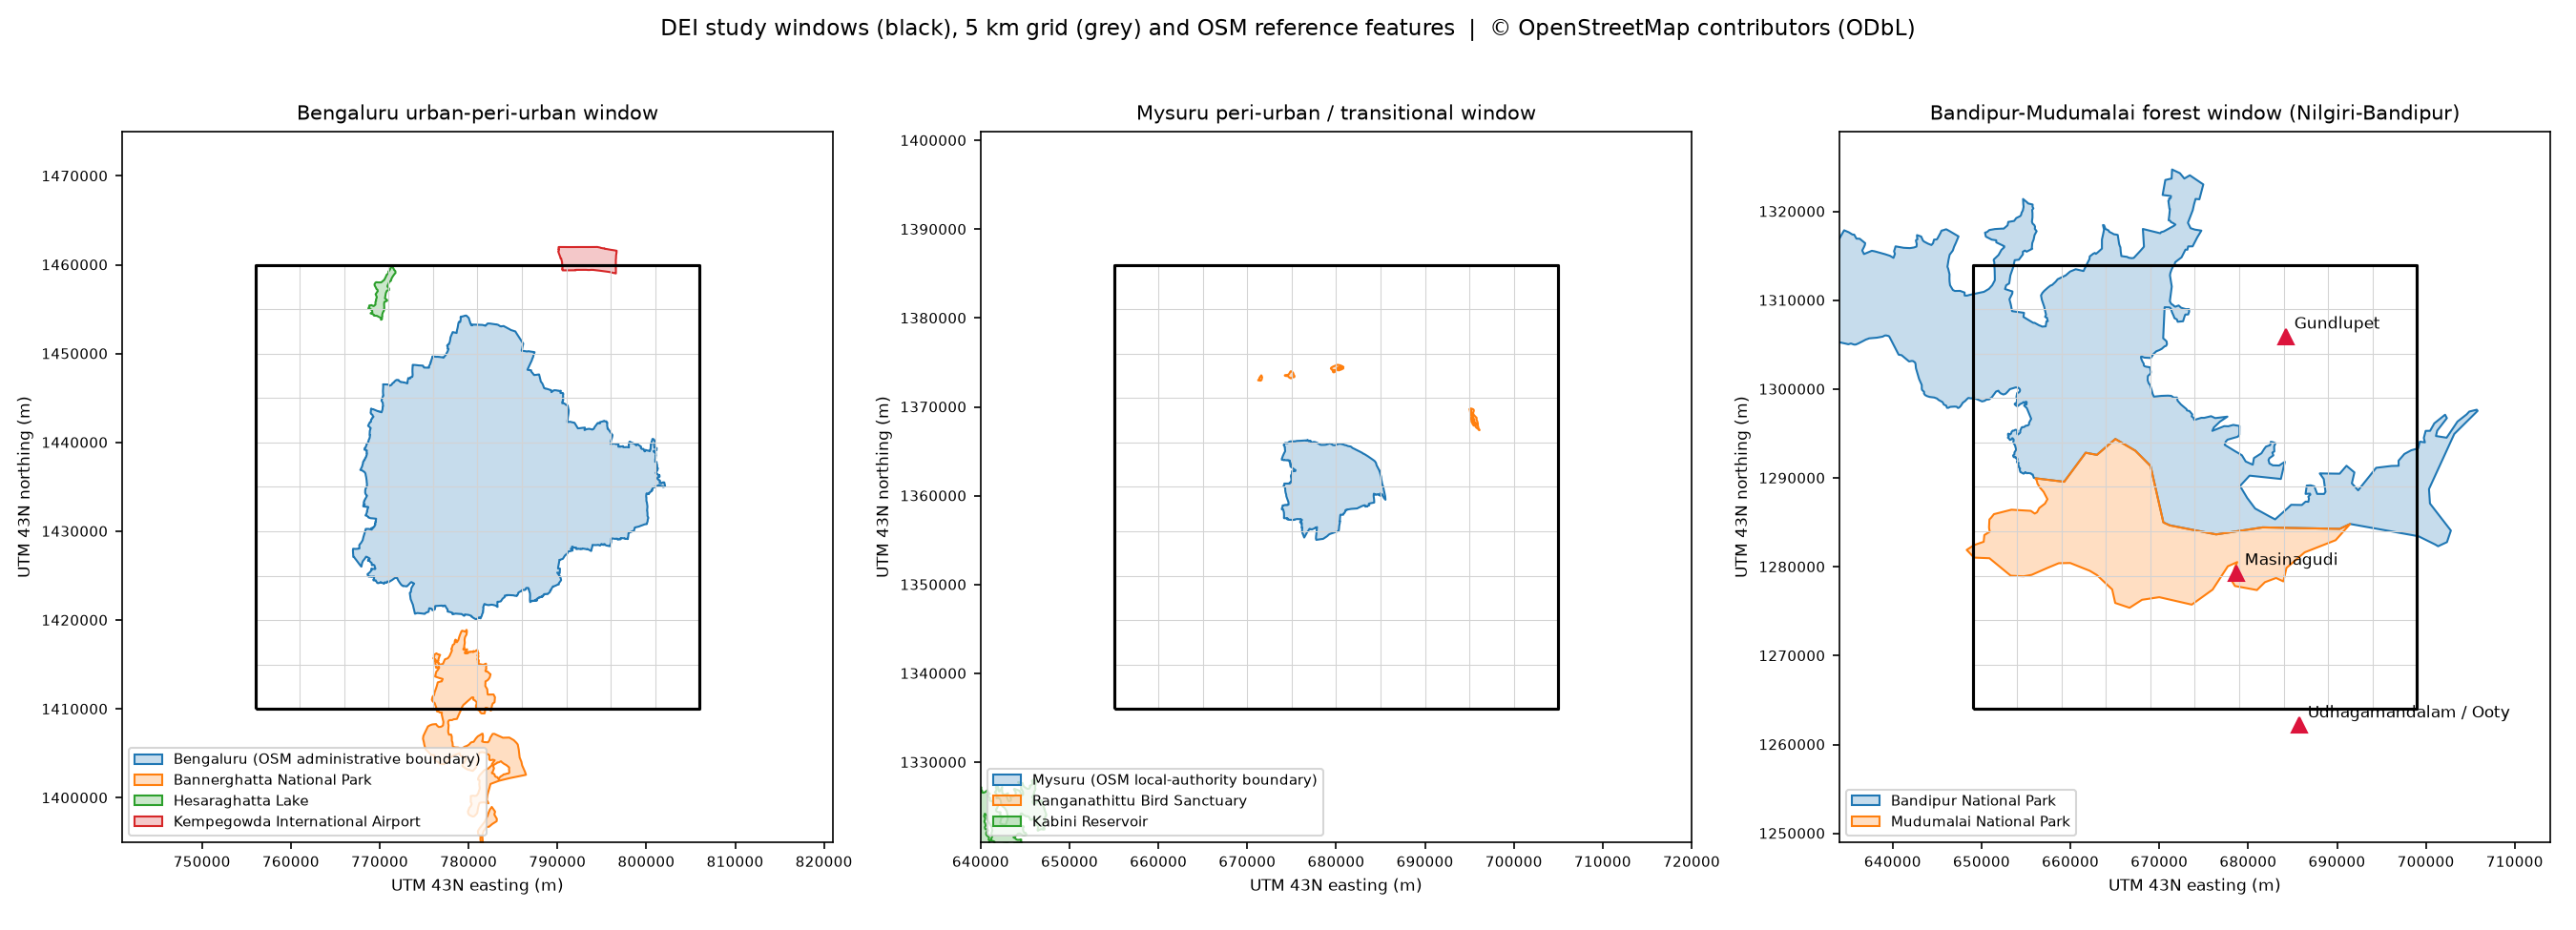

In [6]:
# Display detailed grid and OSM reference features map
ref_fig = P.REPORTS / "phase_1" / "figures" / "study_windows_with_osm_reference.png"
if ref_fig.exists():
    display(Image(filename=str(ref_fig)))

## 4. Central Dataset Inventory & Priority Triage

In strict compliance with **Rule 2: Collect only necessary data**, each dataset is triaged into:
- **Required**: Essential for the primary Spatio-Temporal Graph Neural Network (ST-GNN) model.
- **Optional**: Secondary validation, sensitivity checks, or overlapping data.
- **Reference only**: Contextual qualitative reports (e.g. NTCA Tiger status).

In [7]:
inv = pd.read_csv(P.METADATA / "dataset_inventory.csv")
display(inv[["dataset_id", "category", "dataset_name", "project_priority", "spatial_resolution", "temporal_coverage", "access_requirements"]])

,dataset_id,category,dataset_name,project_priority,spatial_resolution,temporal_coverage,access_requirements
0,HNTL_LI2020,A. Night-time light,Harmonized global night-time light dataset (DMSP + VIIRS-converted),Required,30 arc-second (~1 km),1992 - latest figshare version (see Notebook 03),"Open download, no login"
1,VNL_V2,A. Night-time light,VIIRS Nighttime Lights annual composites (VNL V2.x),Required,15 arc-second (~500 m),2012 (Apr) - latest annual release,Free EOG account required
2,BLACK_MARBLE,A. Night-time light,NASA Black Marble VNP46A3 (monthly) / VNP46A4 (annual),Optional,15 arc-second (~500 m),Jan 2012 - present,Free NASA Earthdata login + token
3,DMSP_OLS_V4,A. Night-time light,DMSP-OLS Version 4 stable lights annual composites,Optional,30 arc-second (~1 km),1992 - 2013,Free EOG account (also on Google Earth Engine: NOAA/DMSP-OLS/NIGHTTIME_...
4,CHEN_VIIRSLIKE,A. Night-time light,Extended NPP-VIIRS-like night-time light series,Optional,~500 m,2000 - 2018 (original paper; later updates to confirm),Open download
5,GBIF,B. Biodiversity occurrence,GBIF occurrence data,Required,Point records (variable uncertainty),Historical - present (irregular),Search API open; bulk downloads need a free GBIF account
6,EBIRD_EBD,B. Biodiversity occurrence,eBird Basic Dataset (EBD) + Sampling Event Data (SED),Required,Point / traveling-count locations,Historical - present; volume grows strongly in recent years (quantified...,eBird account + data request form (eBird states requests are typically ...
7,INAT,B. Biodiversity occurrence,iNaturalist observations (research grade),Optional,Point (threatened taxa obscured),2008 - present (irregular),API open for reading
8,GLOBI,C. Interactions / food webs,Global Biotic Interactions (GloBI),Required,Taxon-level (most records lack coordinates),Undated / literature-based,"Open, no login"
9,MANGAL,C. Interactions / food webs,Mangal ecological network database,Optional,Network/site level,Published networks (various dates),Read API open


In [8]:
# Summary of candidate datasets by category and project priority
summary_priority = pd.crosstab(inv.category, inv.project_priority, margins=True)
display(summary_priority)

project_priority,Optional,Reference only,Required,All
category,,,,
A. Night-time light,3,0,2,5
B. Biodiversity occurrence,1,0,2,3
C. Interactions / food webs,2,0,1,3
D. Species traits,2,0,2,4
E. Environment,0,0,8,8
F. Validation,3,1,0,4
All,11,1,15,27


### 4.1 Temporal Coverage Profile (1992–2024)

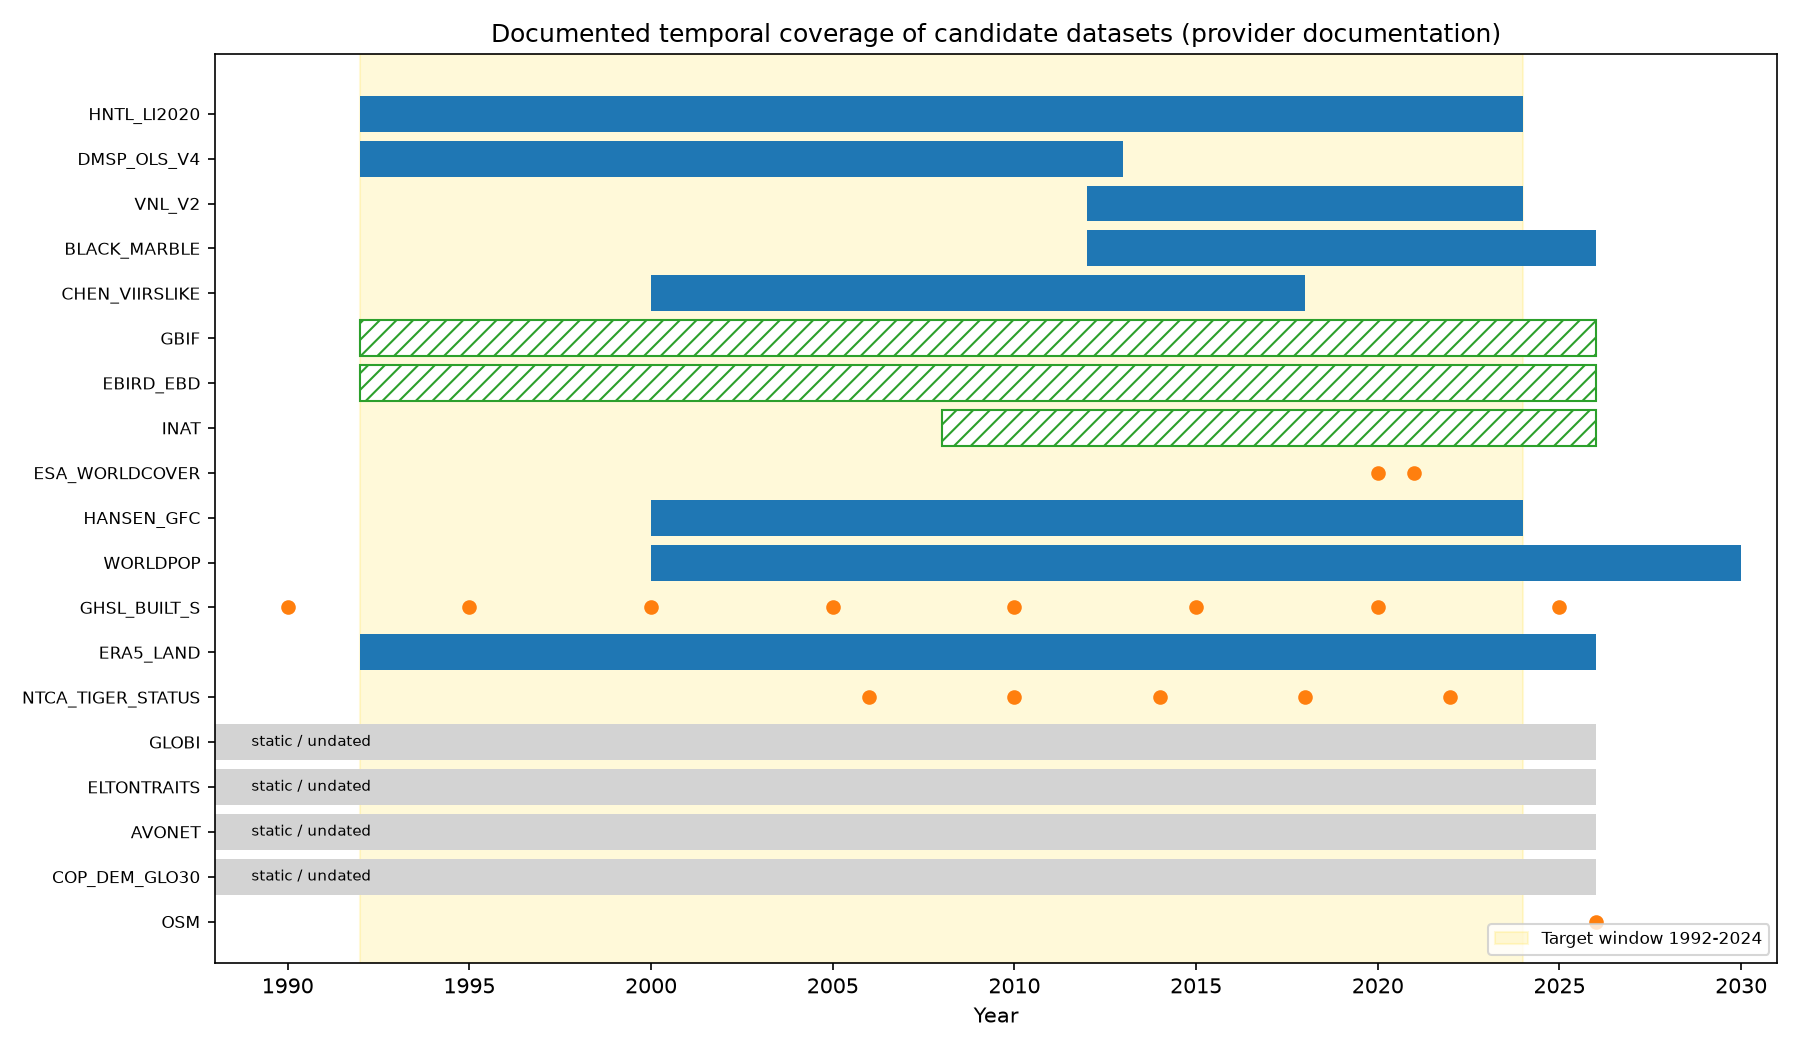

In [9]:
# Display temporal coverage timeline chart
temporal_fig = P.REPORTS / "phase_1" / "figures" / "dataset_temporal_coverage.png"
if temporal_fig.exists():
    display(Image(filename=str(temporal_fig)))

## 5. Regional Availability Matrix

Empirical availability across Bengaluru, Mysuru, and Nilgiri–Bandipur based on live API probes (GBIF, iNaturalist, OSM Overpass, AWS S3).

In [10]:
matrix = pd.read_csv(P.METADATA / "regional_availability_matrix.csv")
display(matrix[["dataset_id", "dataset_name", "bengaluru_availability", "mysuru_availability", "nilgiri_bandipur_availability", "collection_difficulty"]])

,dataset_id,dataset_name,bengaluru_availability,mysuru_availability,nilgiri_bandipur_availability,collection_difficulty
0,HNTL_LI2020,Harmonized global night-time light dataset (DMSP + VIIRS-converted),Confirmed available,Confirmed available,Confirmed available,Low
1,VNL_V2,VIIRS Nighttime Lights annual composites (VNL V2.x),Confirmed available,Confirmed available,Confirmed available,Low
2,BLACK_MARBLE,NASA Black Marble VNP46A3 (monthly) / VNP46A4 (annual),Confirmed available,Confirmed available,Confirmed available,Low
3,DMSP_OLS_V4,DMSP-OLS Version 4 stable lights annual composites,Confirmed available,Confirmed available,Confirmed available,Low
4,CHEN_VIIRSLIKE,Extended NPP-VIIRS-like night-time light series,Confirmed available,Confirmed available,Confirmed available,Low
5,GBIF,GBIF occurrence data,Confirmed available,Confirmed available,Confirmed available,Low (REST API / DOI request)
6,EBIRD_EBD,eBird Basic Dataset (EBD) + Sampling Event Data (SED),Confirmed available,Confirmed available,Confirmed available,Moderate (Requires academic access approval)
7,INAT,iNaturalist observations (research grade),Confirmed available,Confirmed available,Limited coverage (wilderness core restricted),Low
8,GLOBI,Global Biotic Interactions (GloBI),"Likely available, needs verification","Likely available, needs verification","Likely available, needs verification",Low (API name matching)
9,MANGAL,Mangal ecological network database,Limited coverage,Limited coverage,"Likely available, needs verification",Low


### 5.1 Empirical Biodiversity Record Surge

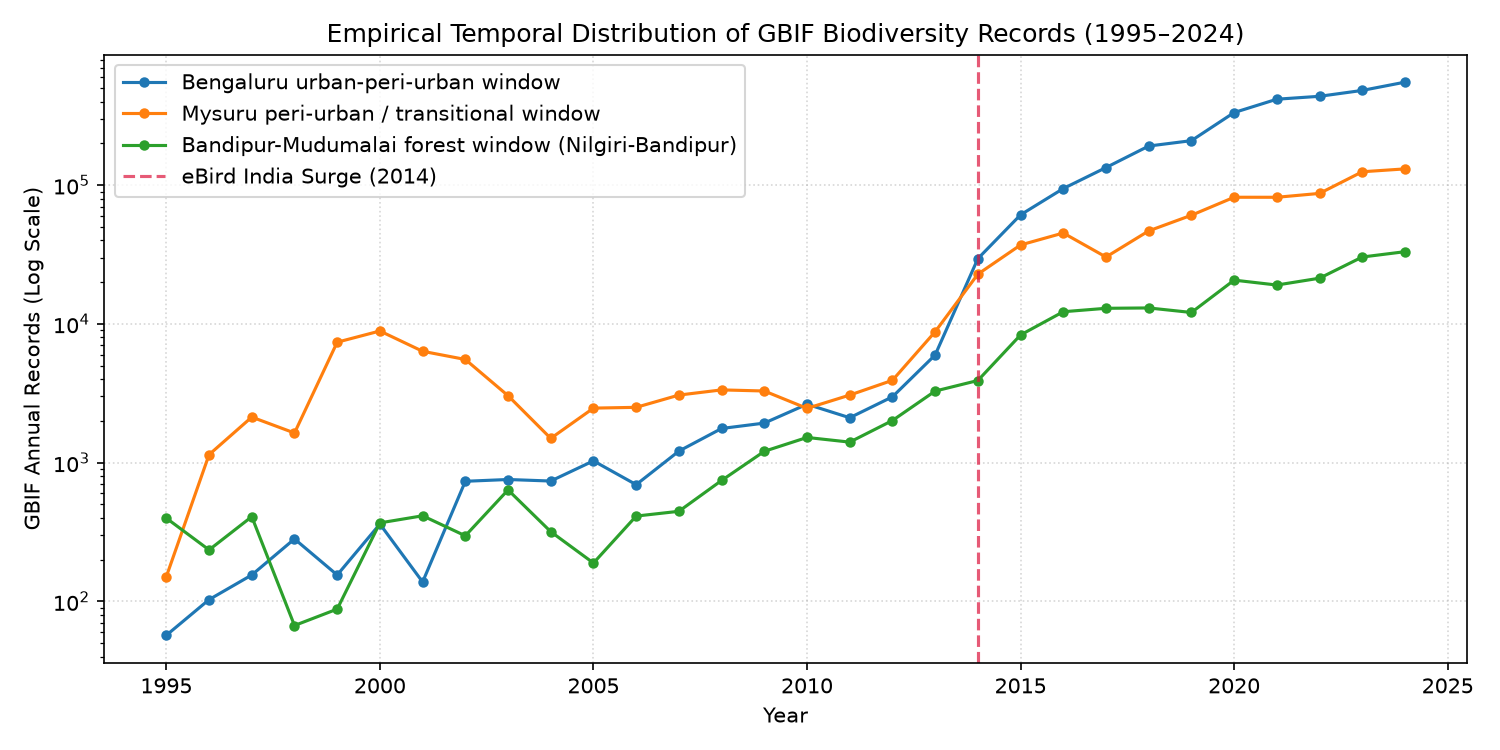

In [11]:
# Display empirical GBIF record surge chart (1995-2024)
surge_fig = P.REPORTS / "phase_1" / "figures" / "gbif_temporal_surge_by_region.png"
if surge_fig.exists():
    display(Image(filename=str(surge_fig)))

## 6. Access Requirements & Obstacles Summary

1. **Authentication Tokens Required Before Phase 2 / 3**:
   - **NASA Earthdata Bearer Token**: Required for Black Marble (VNP46A2/A3/A4) download pipelines.
   - **eBird Academic Request Approval**: Formal access form submission required for the eBird Basic Dataset (EBD) for Karnataka and Tamil Nadu.
   - **Copernicus CDS API Key**: Free user account registration required for ERA5-Land programmatic extraction via `cdsapi`.
2. **Known Scientific Obstacles**:
   - **Monsoon Cloud Cover**: July–September cloudiness impacts optical and nightlight imagery; requires cloud-free coverage weighting.
   - **Citizen Science Effort Bias**: Observations surge after 2014; presence records must be standardized using eBird complete checklists and detection/non-detection occupancy models.
   - **Restricted Camera-Trap Data**: Raw individual camera-trap photo coordinates from NTCA/WII are legally protected; project will use report-level metrics.

## 7. Phase 1 Completion Status

- **Status**: **COMPLETE**.
- **Execution**: All boundary files, grids, inventories, matrix tables, and documentation are verified and reproducible.
- **Integrity**: Zero synthetic data introduced; raw data kept separate from processed data; no code or data pushed to Git.
- **Next Step**: Await user authorization before proceeding to Phase 2 (Nighttime Light Ingestion & Processing).